# Delta Cards pipeline demo

Set one image path, run the pipeline, and inspect the result.

In [10]:
import asyncio
import glob
import os
import sys
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
from IPython.display import display
from PIL import Image

ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "src"))

from delta_cards.recognition.pipeline import CardRecognitionPipeline

## Select a card image

Use a local image path or an `https://` URL.

In [11]:
IMAGE_SOURCE = ROOT / "data/test_image/i6730119854.webp"
IMAGE_SOURCE = str(IMAGE_SOURCE)
IMAGE_SOURCE

'/home/javij/delta-cards/data/test_image/i6730119854.webp'

## Run the pipeline

In [12]:
from delta_cards.recognition.vector_index import USearchCardIndex


def run_pipeline():
    index = USearchCardIndex(ROOT / "data/pokemon_cards.usearch", ROOT / "data/pokemon_cards_meta.sqlite", view_only=True)
    pipeline = CardRecognitionPipeline(vector_index=index)
    return asyncio.run(pipeline.process_card_listing(IMAGE_SOURCE))


result = await asyncio.to_thread(run_pipeline)
result["status"]

Loading /home/javij/delta-cards/models/riftbound_regions.onnx for ONNX Runtime inference...
Using ONNX Runtime 1.30.0 with CPUExecutionProvider


'success'

## Display results

### 1. Original image and BBO detection

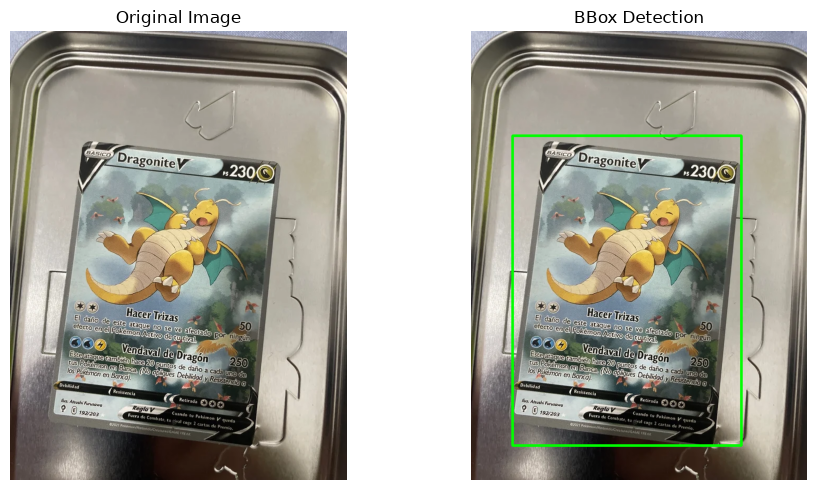

In [13]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))
ax1.imshow(cv2.imread(IMAGE_SOURCE)[:, :, ::-1])
ax1.set_title("Original Image")
ax1.axis("off")

ax2.imshow(result["debug_trace"]["annotated_image"][:, :, ::-1])
ax2.set_title("BBox Detection")
ax2.axis("off")
plt.tight_layout()
plt.show()

### 2. Image candidates from USearch (3x5)

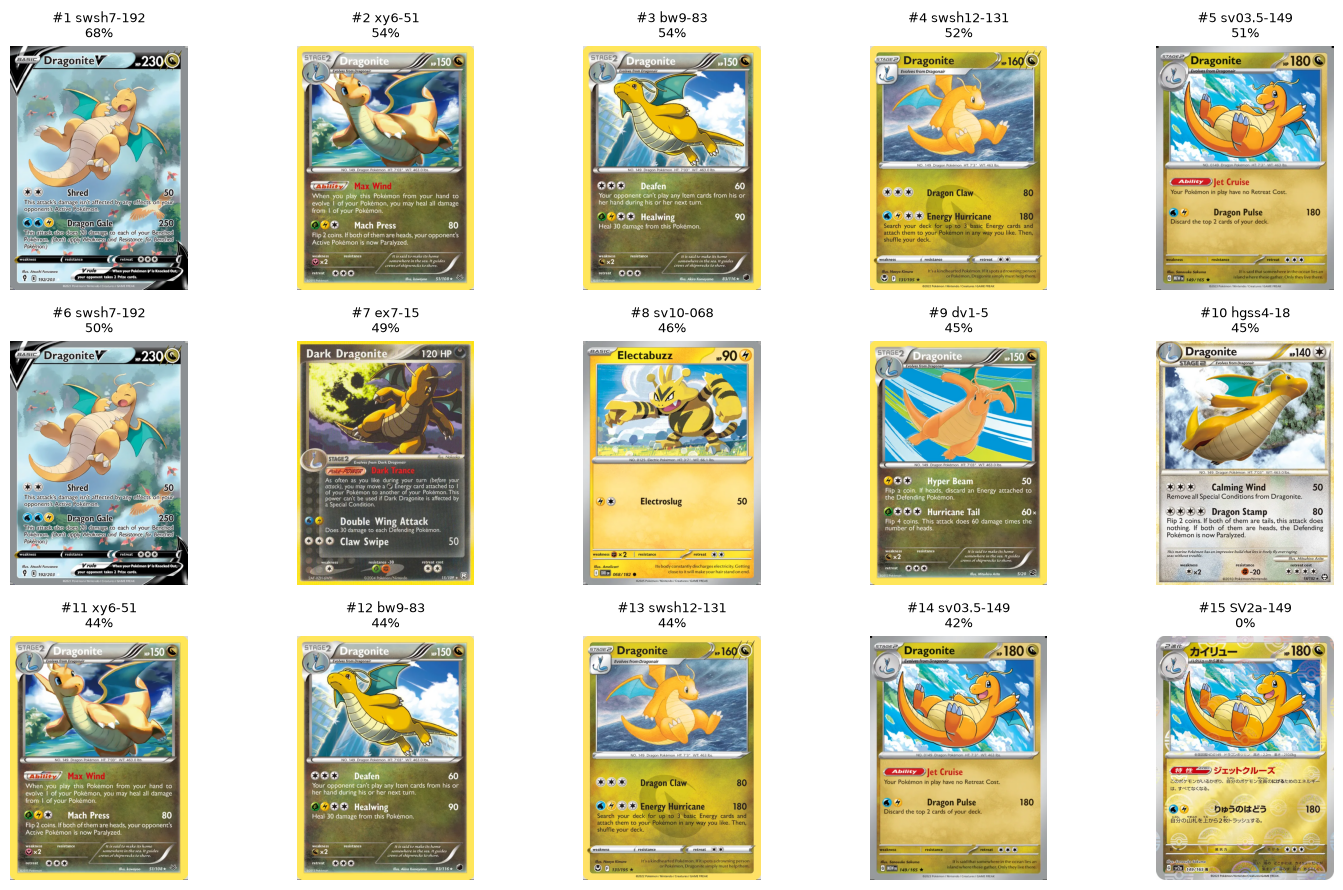

In [14]:
fig, axes = plt.subplots(3, 5, figsize=(15, 9))
for ax, cand in zip(axes.flat, result["debug_trace"]["candidates"][:15]):
    files = glob.glob(f"data/images_cache/*/{cand['tcgdex_id'].replace('-', '_')}.webp")
    if files:
        ax.imshow(cv2.imread(files[0])[:, :, ::-1])
    ax.set_title(f"#{cand['rank']} {cand['tcgdex_id']}\n{cand['combined_score']:.0%}", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

### 3. OCR text from image and candidates with scores

In [15]:
print("--- QUERY OCR TEXT ---")
print(result.get("query_ocr", {}).get("full_text", ""))

print("\n--- CANDIDATES OCR TEXT & SCORES ---")
for cand in result["debug_trace"]["candidates"]:
    print(f"[{cand['rank']}] {cand['tcgdex_id']} (Score: {cand['combined_score']:.0%})")
    print(f"    {cand['full_text']}\n")

--- QUERY OCR TEXT ---
BA5ICO Dragonite 230 Hacer Trizas El dano de este ataque no se ve afectado por nngun efecto ene PokemonAgdvo de tutival. 50 Vendaval de Dragon Esteataguetambienhace2opuntos de dano a cada uno de tus Pokemen cnBanca. (No gplques Debilidad y Resistendag 250 Jos Pokemmon en Bancd! Dtちidd Resist4nk Hs.AlyshFwulgwg Retiradコ 192203 Reglay Fuera de Conbate, tutival toft lcartds dePrtng. Cuandotupok+monvgutdn

--- CANDIDATES OCR TEXT & SCORES ---
[1] swsh7-192 (Score: 68%)
    BASLCO Dragonite 230 PS Hacer Trizas 50 El dano de este ataque no se ve afectado por ningin efecto en el Pokemen Acdivo de tu rival. Vendaval de Dragon 250 Este ataque tambien hace 2o puntos de dano a cada uno de tus Pokemen en Banca. (No apliques Debilidad y Resistendig g Ios Pokemon en Bancal. Debilidad Resistencia Retirada Jus. Afsushi Furusawd Regla V Cuando tu Pokemon yqueda 192/203 Fuera de Combate, tu rival coge 2 cartas de Premio. 92O21PokemOnNintendolCrea+UFeSGAMEFREAK

[2] xy6-51 (Score: 

### 4. LLM verification output

In [16]:
from types import SimpleNamespace
from delta_cards.recognition.llm_verifier import get_llm_verifier

top_cand = result["debug_trace"]["candidates"][0]
llm_res = get_llm_verifier().verify_match(
    offer=SimpleNamespace(),
    query_ocr=result["query_ocr"],
    candidate_ocr={"full_text": top_cand["full_text"]},
)

print(f"Candidate:  {top_cand['tcgdex_id']}")
print(f"Verified:   {llm_res.is_verified}")
print(f"Verdict:    {llm_res.verdict_summary}")
print(f"Confidence: {llm_res.confidence_score:.0f}%")
print(f"Raw Output: {llm_res.raw_response}")

Candidate:  swsh7-192
Verified:   True
Verdict:    Match confirmed
Confidence: 100%
Raw Output: YES


In [17]:
llm_res

LLMVerificationResult(is_verified=True, confidence_score=100.0, confirmed_count=1, total_questions=1, checks={'full_ocr_text_match': True}, questions_detail=[], verdict_summary='Match confirmed', inference_time_s=1.193, raw_response='YES')

## Test an image outside the database

Set an arbitrary local path or public image URL, then rerun the pipeline and display cells above.

In [18]:
# Example: a local image or any public card-image URL.
# IMAGE_SOURCE = "/absolute/path/to/card.jpg"
# IMAGE_SOURCE = "https://example.com/card.jpg"
#
# Rerun the "Run the pipeline" and display cells above.